# Language Models for Information Retrieval
## Topic 2 · Query likelihood · Lecture 2 connection

In this notebook, we use word counts to build a small search experiment. Our main question is simple: **if each document had its own language model, which document would be most likely to generate our query?**

We will compare an unsmoothed model, two smoothing methods, and TF-IDF. We also keep an example where word matching fails, so we can explain the limits clearly.

**How to run:** run all cells from top to bottom. The collection and model code are included here, so this notebook also works by itself with the packages in `requirements.txt`. No API key or dataset download is needed.

**Our scope:** the assignment calls this Topic 2, even though we initially referred to it as Topic 3. The accompanying slides follow the 15-minute structure in the discussion handout.

## 1. What we use from Lecture 2

| Lecture 2 idea | How we use it here |
|---|---|
| Bag-of-words, slides 4–8 | Count each term inside a document. |
| N-gram models, slides 12–17 | Treat a query as text generated by a model. We choose a unigram model for this experiment. |
| Log probabilities, slide 15 | Add logs instead of multiplying many small probabilities. |
| Zero probabilities, slide 18 | A missing query word makes an unsmoothed document score zero. |
| Smoothing, slide 20 | Share probability with unseen words. We compare collection-based smoothing with the lecture's add-one idea. |

A bigram model conditions on the previous word. Our unigram query-likelihood model ignores word order. Both use probability estimates from counts. The classical model here does not generate an answer like a chat model.

## 2. Query likelihood

Let $c(w,d)$ be the count of term $w$ in document $d$, and let $|d|$ be its token count. The maximum-likelihood estimate is

$$P_{MLE}(w\mid d)=\frac{c(w,d)}{|d|}.$$

With the unigram independence assumption, the query score is

$$P(q\mid d)=\prod_{w\in q}P(w\mid d)^{c(w,q)},\qquad
s(d,q)=\sum_{w\in q}c(w,q)\log P(w\mid d).$$

Here the product and sum run over **distinct query terms**. Repeated terms still matter through $c(w,q)$.

Bayes' rule gives $P(d\mid q)\propto P(q\mid d)P(d)$. With equal document priors, we rank by $P(q\mid d)$. This is a modeling assumption, not a guarantee of relevance. Larger log scores are better, so −4 ranks above −8.

Boolean AND retrieval cannot rank partial matches and rejects a document missing any required word. TF-IDF adds weighted matching and cosine similarity. Query likelihood provides a probabilistic way to score the query and makes probability estimation, especially smoothing, explicit. It does not solve all vocabulary or meaning problems.

Background: [Manning et al., Chapter 12](https://nlp.stanford.edu/IR-book/pdf/12lmodel.pdf), building on [Ponte & Croft (1998)](https://ciir.cs.umass.edu/pubfiles/ir-120.pdf).

## 3. Why we smooth

Suppose the query contains `search documents`. A document that contains `search` but never `documents` gets $P(q\mid d)=0$ under MLE. Another document missing `search` also gets zero. We lose the ability to distinguish those partial matches.

Let $P(w\mid C)=c(w,C)/|C|$ be the probability of a word in the whole collection.

**Dirichlet smoothing** adds collection-based pseudo-counts:

$$P_\mu(w\mid d)=\frac{c(w,d)+\mu P(w\mid C)}{|d|+\mu}.$$

Here $\mu>0$ controls the background contribution. The equivalent mixture weight is $\mu/(|d|+\mu)$, so shorter documents receive more smoothing for a fixed $\mu$.

**Jelinek–Mercer (JM)** uses a fixed background weight $\lambda$:

$$P_\lambda(w\mid d)=(1-\lambda)\frac{c(w,d)}{|d|}+\lambda P(w\mid C),\quad 0<\lambda<1.$$

We define $\lambda$ as the **background weight** throughout. Some references reverse this convention.

Lecture 2's add-one method instead gives $(c(w,d)+1)/(|d|+|V|)$ for a unigram model. It uses a uniform vocabulary background. Collection smoothing uses unequal probabilities based on how often terms occur. Smoothing can rescue missing terms in a document only if they occur somewhere in the collection.

Reading: [Zhai & Lafferty (2001)](https://www.cs.cmu.edu/~czhai/paper/sigir2001-smooth.pdf).

In [1]:
from pathlib import Path
import json
import math
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer

pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 140, "font.size": 11})
OUTPUT = Path("results")
ASSETS = Path("assets")
OUTPUT.mkdir(exist_ok=True)
ASSETS.mkdir(exist_ok=True)
print("Setup ready. No network connection is needed.")

Setup ready. No network connection is needed.


## 4. Collection, queries, and relevance labels

We wrote **15 short English documents and 5 queries** for teaching. Documents cover IR concepts, with two insurance/parking examples to show a vocabulary problem. The relevance labels below are our own binary judgments based on each query's intended information need. They are not independent benchmark labels.

For Q1, we consider documents about language modeling and probability relevant, including bigrams and perplexity. For Q3, D15 is relevant because it describes web pages entering an index, though D03 gives the more direct crawler explanation. For Q5, the intended need is vehicle insurance coverage, so D13 is relevant and parking document D14 is not.

We declare the labels before comparing methods. Both methods receive identical text and tokenization: lowercase alphabetic words, no stop-word removal, stemming, or phrase features. This keeps the connection to Lecture 2 clear. It also means `model` and `models` remain different terms.

In [2]:
collection = {'description': 'Handwritten teaching collection. Binary relevance labels are declared by the '
                'author, not benchmark judgments.',
 'documents': {'D01': 'Search engines rank documents for a user query. Ranking helps users '
                      'find relevant information.',
               'D02': 'An inverted index maps each term to documents. The index supports fast '
                      'search over a collection.',
               'D03': 'A web crawler downloads web pages and follows links. Crawling collects '
                      'pages for a search engine.',
               'D04': 'Language models assign probabilities to sequences of words. A unigram '
                      'model uses individual word counts.',
               'D05': 'Query likelihood ranks documents using a document language model. It '
                      'estimates the probability of the query.',
               'D06': 'Smoothing gives probability to unseen words. Dirichlet smoothing '
                      'combines document counts with collection probabilities.',
               'D07': 'A bigram language model predicts a word using the previous word. '
                      'Bigrams preserve local word order.',
               'D08': 'TF IDF weights terms using term frequency and inverse document '
                      'frequency. Cosine similarity compares document and query vectors.',
               'D09': 'BM25 is a ranking function with term frequency saturation and document '
                      'length normalization.',
               'D10': 'Relevance feedback expands a query using relevant documents. Expansion '
                      'can reduce vocabulary mismatch in search.',
               'D11': 'Neural embeddings represent semantic meaning. Dense retrieval can '
                      'match related words with different spellings.',
               'D12': 'Perplexity evaluates how well a language model predicts held out text. '
                      'Lower perplexity means higher average token probability.',
               'D13': 'An automobile insurance policy covers vehicle damage and accident '
                      'liability. Drivers pay a premium for coverage.',
               'D14': 'A car park provides parking spaces near the city market. Visitors '
                      'leave a car while shopping.',
               'D15': 'Web pages contain links and text. An index stores web content so a '
                      'search engine can retrieve pages.'},
 'queries': [{'id': 'Q1',
              'text': 'language model probability',
              'relevant': ['D04', 'D05', 'D07', 'D12']},
             {'id': 'Q2', 'text': 'unseen words smoothing', 'relevant': ['D06']},
             {'id': 'Q3', 'text': 'crawler web pages', 'relevant': ['D03', 'D15']},
             {'id': 'Q4', 'text': 'ranking documents query', 'relevant': ['D01', 'D05']},
             {'id': 'Q5', 'text': 'car coverage', 'relevant': ['D13']}],
 'diagnostic_queries': ['car protection', 'quantum teleportation', 'language quantum']}

documents = collection["documents"]
queries = collection["queries"]
display(pd.DataFrame([{"id": key, "text": value} for key, value in documents.items()]))
display(pd.DataFrame(queries))

,id,text
0,D01,Search engines rank documents for a user query. Ranking helps users find relevant information.
1,D02,An inverted index maps each term to documents. The index supports fast search over a collection.
2,D03,A web crawler downloads web pages and follows links. Crawling collects pages for a search engine.
3,D04,Language models assign probabilities to sequences of words. A unigram model uses individual word...
4,D05,Query likelihood ranks documents using a document language model. It estimates the probability o...
5,D06,Smoothing gives probability to unseen words. Dirichlet smoothing combines document counts with c...
6,D07,A bigram language model predicts a word using the previous word. Bigrams preserve local word order.
7,D08,TF IDF weights terms using term frequency and inverse document frequency. Cosine similarity comp...
8,D09,BM25 is a ranking function with term frequency saturation and document length normalization.
9,D10,Relevance feedback expands a query using relevant documents. Expansion can reduce vocabulary mis...


,id,text,relevant
0,Q1,language model probability,"[D04, D05, D07, D12]"
1,Q2,unseen words smoothing,[D06]
2,Q3,crawler web pages,"[D03, D15]"
3,Q4,ranking documents query,"[D01, D05]"
4,Q5,car coverage,[D13]


## 5. Implementation

The class below estimates document and collection probabilities and ranks all documents. We use natural logs. Exact score ties follow document ID order, so repeated runs give the same result.

**Out-of-vocabulary policy:** ignore query terms absent from the whole collection and report them. A query with no known terms returns no ranking. A partially unknown query uses the remaining terms. This is an explicit practical policy, not something Dirichlet smoothing automatically solves.

TF-IDF uses scikit-learn's defaults for raw term frequency and smoothed IDF, with L2 normalization. Its IDF is $\log((1+N)/(1+df(w)))+1$. The dot product of normalized vectors is cosine similarity. Both methods search the same complete collection.

In [3]:
def tokenize(text):
    """Use exactly the same lowercased word tokens for both retrieval methods."""
    return re.findall(r"[a-z]+", text.lower())


class RetrievalExperiment:
    def __init__(self, documents):
        if not documents or any(not tokenize(text) for text in documents.values()):
            raise ValueError("Provide a nonempty collection with nonempty documents.")
        self.documents = documents
        self.document_ids = sorted(documents)
        self.counts = {}
        self.lengths = {}
        self.collection_counts = Counter()
        for document_id in self.document_ids:
            counts = Counter(tokenize(documents[document_id]))
            self.counts[document_id] = counts
            self.lengths[document_id] = sum(counts.values())
            self.collection_counts.update(counts)
        self.collection_length = sum(self.lengths.values())
        self.vectorizer = TfidfVectorizer(
            tokenizer=tokenize, token_pattern=None, lowercase=False,
            norm="l2", smooth_idf=True, sublinear_tf=False,
        )
        texts = [documents[document_id] for document_id in self.document_ids]
        self.tfidf_matrix = self.vectorizer.fit_transform(texts)

    def prepare_query(self, query):
        tokens = tokenize(query)
        known = [term for term in tokens if term in self.collection_counts]
        unknown = sorted(set(tokens) - set(known))
        return known, unknown

    def term_probability(self, term, document_id, method="dirichlet", mu=20, background_weight=0.2):
        count = self.counts[document_id][term]
        length = self.lengths[document_id]
        collection_probability = self.collection_counts[term] / self.collection_length
        if method == "mle":
            return count / length
        if method == "dirichlet":
            if mu <= 0:
                raise ValueError("mu must be positive.")
            return (count + mu * collection_probability) / (length + mu)
        if method == "jm":
            if not 0 < background_weight < 1:
                raise ValueError("background_weight must be between 0 and 1.")
            return (1 - background_weight) * count / length + background_weight * collection_probability
        raise ValueError("Unknown language model method.")

    def rank(self, query, method="dirichlet", mu=20, background_weight=0.2):
        known, unknown = self.prepare_query(query)
        # An all-OOV query has no evidence. Do not return an arbitrary ranking.
        if not known:
            return [], unknown
        if method == "tfidf":
            query_vector = self.vectorizer.transform([" ".join(known)])
            scores = (self.tfidf_matrix @ query_vector.T).toarray().ravel().tolist()
        else:
            query_counts = Counter(known)
            scores = []
            for document_id in self.document_ids:
                score = 0.0
                for term, frequency in query_counts.items():
                    probability = self.term_probability(term, document_id, method, mu, background_weight)
                    if probability == 0:
                        score = -math.inf
                        break
                    score += frequency * math.log(probability)
                scores.append(score)
        ranking = list(zip(self.document_ids, scores))
        ranking.sort(key=lambda item: (-item[1], item[0]))
        return ranking, unknown

In [4]:
experiment = RetrievalExperiment(documents)
print("Documents:", len(documents))
print("Tokens:", experiment.collection_length)
print("Vocabulary:", len(experiment.collection_counts))
print("Average document length:", round(experiment.collection_length / len(documents), 2))
display(pd.DataFrame({"document": experiment.document_ids,
                      "length": [experiment.lengths[d] for d in experiment.document_ids]}))

Documents: 15
Tokens: 235
Vocabulary: 146
Average document length: 15.67


,document,length
0,D01,14
1,D02,16
2,D03,16
3,D04,15
4,D05,16
5,D06,14
6,D07,16
7,D08,18
8,D09,13
9,D10,15


## 6. One calculation we can explain by hand

We use a separate three-document collection here to keep the arithmetic short:

- A: `search engines rank documents documents`
- B: `search engines index web pages`
- C: `language models rank documents`

There are 14 tokens in total. `search` occurs twice and `documents` occurs three times. For query `search documents`, document C has no `search`, so its MLE query probability is zero. With $\mu=5$, it receives a small background probability instead.

This cell checks the arithmetic directly against our implementation.

In [5]:
small = RetrievalExperiment({
    "A": "search engines rank documents documents",
    "B": "search engines index web pages",
    "C": "language models rank documents",
})
rows = []
for document_id in small.document_ids:
    p_search = small.term_probability("search", document_id, mu=5)
    p_documents = small.term_probability("documents", document_id, mu=5)
    rows.append({"document": document_id, "P(search|d)": p_search,
                 "P(documents|d)": p_documents,
                 "P(query|d)": p_search * p_documents,
                 "log score": math.log(p_search) + math.log(p_documents)})
worked = pd.DataFrame(rows)
display(worked.round(6))
assert small.collection_length == 14
assert math.isclose(rows[2]["P(search|d)"], (5 * 2 / 14) / 9)
assert math.isclose(rows[2]["P(documents|d)"], (1 + 5 * 3 / 14) / 9)
assert small.rank("search documents", "mle")[0][2][1] == -math.inf

,document,P(search|d),P(documents|d),P(query|d),log score
0,A,0.171429,0.307143,0.052653,-2.944031
1,B,0.171429,0.107143,0.018367,-3.997181
2,C,0.079365,0.230159,0.018267,-4.002683


## 7. Main experiment

We compare TF-IDF, MLE, JM with background weight 0.2, and Dirichlet with $\mu=20$. Average document length is about 16 tokens, so 20 is an illustrative value on the same scale. We set it for demonstration, not as an optimum selected on these queries.

The output includes every score and rank. Scores from different models have different meanings and should not be compared numerically across models. We compare ranked lists and relevance metrics.

In [6]:
methods = {"TF-IDF": "tfidf", "MLE": "mle", "JM (0.2)": "jm", "Dirichlet (20)": "dirichlet"}
ranking_rows = []
for query in queries:
    for label, method in methods.items():
        ranking, unknown = experiment.rank(query["text"], method=method)
        for rank, (document_id, score) in enumerate(ranking, start=1):
            ranking_rows.append({"query": query["id"], "method": label,
                "rank": rank, "document": document_id, "score": score,
                "relevant": document_id in query["relevant"]})
rankings = pd.DataFrame(ranking_rows)
rankings.to_csv(OUTPUT / "rankings.csv", index=False)
display(rankings[rankings["rank"] <= 3].pivot_table(
    index=["query", "rank"], columns="method", values="document", aggfunc="first"))
zero_count = rankings[(rankings["method"] == "MLE") & (rankings["score"] == -math.inf)].groupby("query").size()
print("MLE zero-probability documents by query:")
print(zero_count.to_string())

method     Dirichlet (20) JM (0.2)  MLE TF-IDF
query rank                                    
Q1    1               D05      D05  D05    D05
      2               D12      D12  D12    D12
      3               D04      D04  D01    D04
Q2    1               D06      D06  D06    D06
      2               D11      D11  D01    D04
      3               D04      D04  D02    D11
Q3    1               D03      D03  D03    D03
      2               D15      D15  D01    D15
      3               D09      D01  D02    D01
Q4    1               D01      D01  D01    D01
      2               D05      D05  D02    D05
      3               D10      D10  D03    D10
Q5    1               D13      D13  D01    D14
      2               D14      D14  D02    D13
      3               D09      D01  D03    D01

MLE zero-probability documents by query:
query
Q1    13
Q2    14
Q3    14
Q4    14
Q5    15


## 8. Evaluation

For each query, **P@3** is the number of relevant documents in the first three results divided by 3. **Recall@3** divides those hits by the total number of relevant documents. With only one relevant document, the highest possible P@3 is 1/3.

**Reciprocal rank (RR)** is 1 divided by the position of the first relevant document. **Average precision (AP)** averages precision at every relevant document's rank over the number of relevant documents. We compute AP over all 15 results. Their means across queries are MRR and MAP.

We retain zero cosine scores and negative-infinity MLE scores at the bottom of the lists. Their document-ID tie order can affect metrics. MLE's results therefore illustrate the zero-probability problem, not reliable ordering within its tied tail. No significance claim is possible from five handwritten queries.

In [7]:
def evaluate(ranking, relevant, k=3):
    relevant = set(relevant)
    if not relevant:
        raise ValueError("Evaluation requires at least one relevant document.")
    hits = 0
    average_precision = 0.0
    reciprocal_rank = 0.0
    top_hits = 0
    for rank, (document_id, _) in enumerate(ranking, start=1):
        if document_id in relevant:
            hits += 1
            average_precision += hits / rank
            if reciprocal_rank == 0:
                reciprocal_rank = 1 / rank
            if rank <= k:
                top_hits += 1
    return {"P@3": top_hits / k, "Recall@3": top_hits / len(relevant),
            "AP": average_precision / len(relevant), "RR": reciprocal_rank}

,P@3,Recall@3,MAP,MRR
method,,,,
TF-IDF,0.600,0.95,0.900,0.900
MLE,0.333,0.50,0.619,0.815
JM (0.2),0.600,0.95,1.000,1.000
Dirichlet (20),0.600,0.95,1.000,1.000


method,Dirichlet (20),JM (0.2),MLE,TF-IDF
query,,,,
Q1,1.0,1.0,1.000,1.0
Q2,1.0,1.0,1.000,1.0
Q3,1.0,1.0,1.000,1.0
Q4,1.0,1.0,1.000,1.0
Q5,1.0,1.0,0.077,0.5


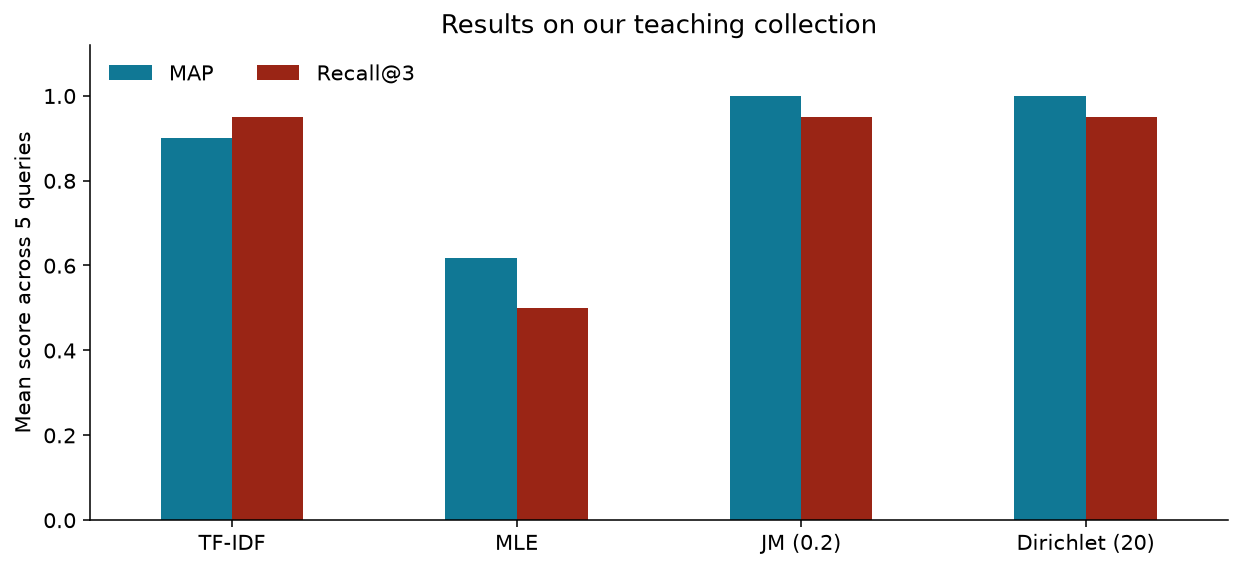

In [8]:
metric_rows = []
for query in queries:
    for label, method in methods.items():
        ranking, _ = experiment.rank(query["text"], method=method)
        metric_rows.append({"query": query["id"], "method": label,
                            **evaluate(ranking, query["relevant"])})
metrics = pd.DataFrame(metric_rows)
summary = metrics.groupby("method", sort=False)[["P@3", "Recall@3", "AP", "RR"]].mean()
summary = summary.rename(columns={"AP": "MAP", "RR": "MRR"})
metrics.to_csv(OUTPUT / "per_query_metrics.csv", index=False)
summary.to_csv(OUTPUT / "summary.csv")
display(summary.round(3))
display(metrics.pivot(index="query", columns="method", values="RR").round(3))

fig, ax = plt.subplots(figsize=(9, 4.2))
summary[["MAP", "Recall@3"]].plot.bar(ax=ax, color=["#107895", "#9a2515"], rot=0)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Mean score across 5 queries")
ax.set_xlabel("")
ax.set_title("Results on our teaching collection")
ax.legend(loc="upper left", ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(ASSETS / "comparison.png", dpi=180)
plt.show()

### What the results show

TF-IDF and smoothed query likelihood retrieve the same relevant documents in their first three results across our five queries. Their mean Recall@3 is 0.95. Query likelihood improves the first relevant rank for Q5, which raises MAP and MRR from 0.90 to 1.00 on this small collection.

For Q5, TF-IDF ranks the parking document D14 first because `car` occurs twice there. The intended insurance document D13 contains `coverage` but uses `automobile` instead of `car`. Smoothing allows both query terms to contribute without making D13's whole query probability zero. This result does **not** mean the model learned that `car` means `automobile`.

MLE cannot distinguish many partial matches. Its reported scores depend strongly on the deterministic order of zero-probability ties. We should explain that weakness when presenting the comparison.

## 9. Smoothing sensitivity

We vary $\mu$ without changing documents or labels. This is an illustrative sensitivity analysis on the same small collection, not a held-out tuning procedure. A proper study would choose parameters on development queries and report final results on separate test queries.

As $\mu$ approaches zero, estimates approach MLE. As it becomes very large, each document approaches the collection distribution and score differences shrink. Finite large values can still produce different rankings.

In [9]:
sensitivity_rows = []
for mu in [0.1, 1, 5, 20, 100, 1000]:
    values = []
    for query in queries:
        ranking, _ = experiment.rank(query["text"], mu=mu)
        values.append(evaluate(ranking, query["relevant"]))
    sensitivity_rows.append({"mu": mu, "MAP": sum(v["AP"] for v in values) / len(values),
                             "Recall@3": sum(v["Recall@3"] for v in values) / len(values)})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUTPUT / "sensitivity.csv", index=False)
display(sensitivity.round(3))

lines = ["| $\\mu$ | MAP | Recall@3 |", "|---:|---:|---:|"]
for row in sensitivity.itertuples():
    lines.append(f"| {row.mu:g} | {row.MAP:.3f} | {row[3]:.3f} |")
(OUTPUT / "sensitivity-slide.md").write_text("\n".join(lines) + "\n")

,mu,MAP,Recall@3
0,0.1,1.0,0.95
1,1.0,1.0,0.95
2,5.0,1.0,0.95
3,20.0,1.0,0.95
4,100.0,1.0,0.95
5,1000.0,1.0,0.95


184

## 10. A failure case and unknown words

For `car protection`, our intended target is still the insurance document D13. `protection` is outside the collection, so the declared OOV policy drops it. Both methods then rely on `car` and favor the parking document. Smoothing gives unseen terms background mass, but it cannot infer a synonym relationship.

We also try a fully unknown query and a mixed query. Returning no results for a fully unknown query is more honest than displaying a document-ID ranking with no evidence.

In [10]:
for query in collection["diagnostic_queries"]:
    print("\nQuery:", query)
    for label, method in [("TF-IDF", "tfidf"), ("Dirichlet", "dirichlet")]:
        ranking, unknown = experiment.rank(query, method)
        print(label, "ignored terms:", unknown, "top 3:", ranking[:3])


Query: car protection
TF-IDF ignored terms: ['protection'] top 3: [('D14', 0.49831174218044305), ('D01', 0.0), ('D02', 0.0)]
Dirichlet ignored terms: ['protection'] top 3: [('D14', -2.8086937268818977), ('D09', -5.267213621496703), ('D01', -5.297066584646384)]

Query: quantum teleportation
TF-IDF ignored terms: ['quantum', 'teleportation'] top 3: []
Dirichlet ignored terms: ['quantum', 'teleportation'] top 3: []

Query: language quantum
TF-IDF ignored terms: ['quantum'] top 3: [('D04', 0.20843511458955452), ('D05', 0.20343391278867942), ('D07', 0.17490912139282014)]
Dirichlet ignored terms: ['quantum'] top 3: [('D04', -3.2623609368079394), ('D05', -3.2905318137746358), ('D07', -3.2905318137746358)]


## 11. Checks for correctness

These checks verify probability normalization, the manual calculation, repeated query terms, consistent tokenization, valid relevance labels, and unknown-query handling. They do not prove that our relevance judgments represent real users.

In [11]:
for document_id in experiment.document_ids:
    for method in ["mle", "jm", "dirichlet"]:
        total = sum(experiment.term_probability(term, document_id, method)
                    for term in experiment.collection_counts)
        assert math.isclose(total, 1.0, abs_tol=1e-12)
assert tokenize("Language, MODELS!") == ["language", "models"]
assert experiment.rank("quantum teleportation")[0] == []
assert experiment.rank("")[0] == []
one, _ = experiment.rank("language", mu=20)
two, _ = experiment.rank("language language", mu=20)
assert [d for d, _ in one] == [d for d, _ in two]
assert all(math.isclose(dict(two)[d], 2 * score) for d, score in one)
for query in queries:
    assert set(query["relevant"]) <= set(documents)
    for method in ["jm", "dirichlet"]:
        assert all(math.isfinite(score) for _, score in experiment.rank(query["text"], method)[0])
assert math.isclose(summary.loc["TF-IDF", "MAP"], 0.9)
assert math.isclose(summary.loc["Dirichlet (20)", "MAP"], 1.0)
print("All checks passed.")

All checks passed.


## 12. Limitations, comparison, and use in IR

| Method | Main idea | Practical limitation |
|---|---|---|
| Boolean AND | Require every query term | No graded ranking of partial matches |
| TF-IDF cosine | Compare weighted term vectors | Exact vocabulary matching and weighting choices |
| Unigram query likelihood | Estimate the probability of the query under each document model | Smoothing choice, word order loss, and vocabulary mismatch |
| BM25 | Saturated term frequency with length normalization | Still mainly lexical matching and has tuning parameters |

Query likelihood and TF-IDF both use sparse counts, so neither automatically understands meaning. Our experiment also has a tiny collection, short English documents, manually declared labels, no held-out test set, and no latency measurements. It cannot tell us which method is best for a real search service. English tokenization here is not suitable for Khmer text without a segmentation strategy.

**Real system:** Indri, from the Lemur Project, documents query-likelihood scoring with Dirichlet smoothing. Its default $\mu=2500$ is a toolkit setting, not a recommendation for these short documents. Indri is a documented research-system example. We are not claiming it represents every current commercial search engine.

See [Indri scoring documentation](https://sourceforge.net/p/lemur/wiki/Indri%20Document%20Scoring/) and [Indri query language](https://www.lemurproject.org/lemur/IndriQueryLanguage.php).

**What we learned:** a document language model gives us a clear way to rank queries using probabilities. Smoothing is essential for partial matches. Next, we could use a judged benchmark, tune on development queries, compare BM25, and test query expansion or dense retrieval for vocabulary mismatch.

## 13. Practice for the defense

1. **Why use unigrams when Lecture 2 teaches bigrams?** Unigrams need fewer counts and suit short queries. Bigrams retain local order but make sparse estimation harder. This is a modeling choice, not a claim that order never matters.
2. **Why do we add logs?** The logarithm preserves ranking and turns products into sums. It also avoids numerical underflow. It does not remove zero probabilities.
3. **Does smoothing make every unknown word possible?** Only terms supported by the chosen background get positive probability. Fully unseen collection terms need a separate policy.
4. **Why is $\mu=20$ not 2500?** Our documents average about 16 words. We use a small illustrative pseudo-count strength and show sensitivity. Real settings need validation.
5. **Does lower perplexity prove better retrieval?** No. Perplexity measures text prediction. We evaluate retrieval using relevance-based metrics.
6. **Did query likelihood beat TF-IDF?** It improved first relevant rank on Q5 and tied on the other four queries. This toy result cannot support a general superiority claim.
7. **Can we compare −6 from one query with −4 from another?** Not as relevance confidence. Query length and term probabilities affect score scale.
8. **What happens if document priors differ?** Add $\log P(d)$ to the query-likelihood log score. We assume equal priors here.

## References

1. DORN Dawin. *Lecture 2: NLP Foundations I: Bag-of-Words and Language Models*. ITC, October 13, 2026. Supplied course PDF, especially slides 4–8 and 12–20.
2. *Group Discussion Topics: Retrieval Models*. Supplied handout, pages 1 and 3. Topic 2 requirements and presentation structure.
3. Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*, Chapter 12. [Book chapter](https://nlp.stanford.edu/IR-book/pdf/12lmodel.pdf).
4. Ponte, J. M., & Croft, W. B. (1998). A Language Modeling Approach to Information Retrieval. *SIGIR*, 275–281. [Original paper](https://ciir.cs.umass.edu/pubfiles/ir-120.pdf), [DOI](https://doi.org/10.1145/290941.291008).
5. Zhai, C., & Lafferty, J. (2001). A Study of Smoothing Methods for Language Models Applied to Ad Hoc Information Retrieval. *SIGIR*, 334–342. [Paper](https://www.cs.cmu.edu/~czhai/paper/sigir2001-smooth.pdf).
6. Lemur Project. [Indri Document Scoring](https://sourceforge.net/p/lemur/wiki/Indri%20Document%20Scoring/) and [query language reference](https://www.lemurproject.org/lemur/IndriQueryLanguage.php). Accessed November 3, 2026.
7. Scikit-learn. [TfidfVectorizer API](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html). Baseline implementation details.

The text collection and all numerical results in this notebook are our teaching example, not results quoted from the papers. The provided course PDFs remain local reference material and are not uploaded to this repository.